# UTS Graf Sains Data: Python Driver Neo4j dan Rekomendasi

**Nama / NIM:** Ahmad Marannuang Tajibu/ (23031554040)



In [1]:
import sys
import neo4j

print("Python       :", sys.version)
print("Lokasi Python:", sys.executable)
print("neo4j        :", neo4j.__version__)
print("Punya execute_query?", hasattr(neo4j.Driver, "execute_query"))

Python       : 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
Lokasi Python: /home/ahmad/Documents/graf/uts/myenv/bin/python
neo4j        : 6.4.1
Punya execute_query? True


In [4]:
from neo4j import GraphDatabase, RoutingControl
from getpass import getpass

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", getpass("Password Neo4j: "))

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    print("Koneksi berhasil!")

Koneksi berhasil!


In [5]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

In [6]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


In [7]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    records, _, _ = driver.execute_query(
        "SHOW DATABASES YIELD name, currentStatus",
        database_="system", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["name"], "-", record["currentStatus"])

movie - online
neo4j - online
system - online


### Pertanyaan Pendahuluan (Checkpoint)

**1. Apa nama database yang digunakan pada tutorial ini?**

Database yang digunakan bernama **`neo4j`**. Ini terlihat dari parameter `database_="neo4j"` pada fungsi `add_friend` dan `print_friends`. `neo4j` adalah database default yang otomatis dibuat oleh Neo4j.

Hasil `SHOW DATABASES` pada instance `gsd` menunjukkan ada 3 database dalam 1 instance, yaitu `movie`, `neo4j` (dipakai tutorial), dan `system` (database internal untuk mengelola database lain). Semuanya berstatus `online`.

In [8]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    # Cara 1: lewat parameter Python database_
    r1, _, _ = driver.execute_query(
        "MATCH (n) RETURN count(n) AS total",
        database_="movie", routing_=RoutingControl.READ,
    )
    print("Cara 1 (database_) :", r1[0]["total"])

    # Cara 2: lewat sintaks Cypher USE, sambil "berdiri" di database neo4j
    r2, _, _ = driver.execute_query(
        "USE movie MATCH (n) RETURN count(n) AS total",
        database_="neo4j", routing_=RoutingControl.READ,
    )
    print("Cara 2 (USE movie) :", r2[0]["total"])

Cara 1 (database_) : 10372
Cara 2 (USE movie) : 10372


**2. Sebutkan akses lain (seperti sintaks DDL/DML Cypher) yang dapat digunakan untuk mengakses database lain dalam 1 instance!**

Selain parameter Python `database_="..."`, ada beberapa cara lain.

**a) Klausa `USE` pada Cypher (DML / query data)**

```cypher
USE movie
MATCH (n) RETURN count(n) AS total
```

`USE <nama_database>` harus menjadi klausa pertama dalam query. Query diarahkan ke database tujuan walaupun koneksi berada di database lain.

**b) Menentukan database saat membuat session di driver Python**

```python
with driver.session(database="movie") as session:
    session.run("MATCH (n) RETURN count(n) AS total")
```

**c) Perintah administrasi database (DDL), dijalankan lewat database `system`**

```cypher
SHOW DATABASES
CREATE DATABASE nama_db IF NOT EXISTS
START DATABASE nama_db
STOP DATABASE nama_db
DROP DATABASE nama_db IF EXISTS
```

**d) Di Neo4j Browser / cypher-shell**, ganti database aktif dengan `:use movie`.

**Pembuktian:** pada instance `gsd`, query `MATCH (n) RETURN count(n)` ke database `movie` lewat `database_="movie"` (cara Python) dan lewat `USE movie` (cara Cypher) sama-sama menghasilkan **10372** node. Jadi kedua cara setara.

In [10]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    # Semua relasi KNOWS beserta arahnya
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[r:KNOWS]->(b:Person) "
        "RETURN a.name AS dari, type(r) AS relasi, b.name AS ke ORDER BY ke",
        database_="neo4j", routing_=RoutingControl.READ,
    )
    for rec in records:
        print(rec["dari"], f"-[{rec['relasi']}]->", rec["ke"])

    # Adakah relasi sebaliknya (teman mengenal balik Arthur)?
    balik, _, _ = driver.execute_query(
        "MATCH (b:Person)-[:KNOWS]->(a:Person {name: 'Arthur'}) "
        "RETURN count(*) AS jumlah",
        database_="neo4j", routing_=RoutingControl.READ,
    )
    print("Relasi balik ke Arthur:", balik[0]["jumlah"])

Arthur -[KNOWS]-> Guinevere
Arthur -[KNOWS]-> Lancelot
Arthur -[KNOWS]-> Merlin
Relasi balik ke Arthur: 0


**3. Apa jenis graf pertemanan yang telah dibuat di sini?**

Graf yang dibuat adalah **graf berarah (*directed graph*)**, dengan ciri berikut:

- **Berarah.** Relasi ditulis `(a)-[:KNOWS]->(friend)`, jadi garisnya punya arah dari orang ke temannya. Hasil query menunjukkan `Arthur -[KNOWS]-> Guinevere`, `Lancelot`, dan `Merlin`, sedangkan relasi balik ke Arthur berjumlah **0**. Artinya "Arthur mengenal Guinevere" tidak otomatis berarti "Guinevere mengenal Arthur".
- **Homogen.** Hanya ada satu label simpul (`Person`) dan satu tipe relasi (`KNOWS`).
- **Tidak berbobot.** Relasi `KNOWS` tidak membawa properti apa pun, jadi semua garis setara.
- **Bentuk bintang (*star*).** Arthur menjadi pusat dengan 3 garis keluar, sedangkan tiga temannya masing-masing hanya punya 1 garis masuk.

Catatan: di Neo4j, setiap relasi selalu tersimpan dengan arah. Kalau ingin memperlakukannya sebagai graf tak berarah, cukup tulis query tanpa panah, misalnya `(a)-[:KNOWS]-(b)`.

In [11]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    sebelum, _, _ = driver.execute_query(
        "MATCH (n) RETURN count(n) AS total",
        database_="neo4j", routing_=RoutingControl.READ,
    )
    jumlah = sebelum[0]["total"]
    print("Node sebelum reset:", jumlah)

    if jumlah <= 10:
        driver.execute_query("MATCH (n) DETACH DELETE n", database_="neo4j")
        sesudah, _, _ = driver.execute_query(
            "MATCH (n) RETURN count(n) AS total",
            database_="neo4j", routing_=RoutingControl.READ,
        )
        print("Node sesudah reset:", sesudah[0]["total"])
    else:
        print("Isi database neo4j banyak, reset dibatalkan. Cek dulu isinya.")

Node sebelum reset: 4
Node sesudah reset: 0


***SELESAIII 1.2***

In [13]:
import pandas as pd

df = pd.read_csv("data/events.csv")

print("Bentuk (baris, kolom):", df.shape)
print()
print(df.dtypes)
print()
print(df.head())
print()
print("Jumlah per jenis event:", df["event"].value_counts().to_dict())
print("Waktu paling awal :", pd.to_datetime(df["timestamp"].min(), unit="ms"))
print("Waktu paling akhir:", pd.to_datetime(df["timestamp"].max(), unit="ms"))

Bentuk (baris, kolom): (2756101, 5)

timestamp          int64
visitorid          int64
event                str
itemid             int64
transactionid    float64
dtype: object

       timestamp  visitorid event  itemid  transactionid
0  1433221332117     257597  view  355908            NaN
1  1433224214164     992329  view  248676            NaN
2  1433221999827     111016  view  318965            NaN
3  1433221955914     483717  view  253185            NaN
4  1433221337106     951259  view  367447            NaN

Jumlah per jenis event: {'view': 2664312, 'addtocart': 69332, 'transaction': 22457}
Waktu paling awal : 2015-05-03 03:00:04.384000
Waktu paling akhir: 2015-09-18 02:59:47.788000


In [14]:
import os

SOURCE = "data"
csv_file_path = os.path.join(SOURCE, "events.csv")
print("File events.csv ada?", os.path.exists(csv_file_path))

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    with driver.session(database="neo4j") as session:
        hasil = session.run("RETURN 1 AS tes").single()["tes"]
    print("Session berhasil, hasil tes =", hasil)

File events.csv ada? True
Session berhasil, hasil tes = 1


In [15]:
def create_constraints(session):
    session.run(
        "CREATE CONSTRAINT visitor_id IF NOT EXISTS "
        "FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE"
    )
    session.run(
        "CREATE CONSTRAINT item_id IF NOT EXISTS "
        "FOR (i:Item) REQUIRE i.itemId IS UNIQUE"
    )

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        create_constraints(session)
        for rec in session.run(
            "SHOW CONSTRAINTS YIELD name, labelsOrTypes, properties"
        ):
            print(rec["name"], rec["labelsOrTypes"], rec["properties"])

item_id ['Item'] ['itemId']
visitor_id ['Visitor'] ['visitorId']


In [16]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

In [18]:
sampel = pd.read_csv("data/events.csv", nrows=1000)

# Rapikan transactionid: kosong jadi "", angka jadi teks tanpa ".0"
sampel["transactionid"] = sampel["transactionid"].apply(
    lambda x: "" if pd.isna(x) else str(int(x))
)
print("Event di sampel:", sampel["event"].value_counts().to_dict())

records = sampel.to_dict(orient="records")

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        session.execute_write(import_batch, records)

        print("\nNode:")
        for rec in session.run("MATCH (n) RETURN labels(n)[0] AS jenis, count(*) AS jumlah"):
            print(" ", rec["jenis"], rec["jumlah"])

        print("Relasi:")
        for rec in session.run("MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah"):
            print(" ", rec["relasi"], rec["jumlah"])

        # Bersihkan data uji supaya impor sungguhan nanti tidak dobel
        session.run("MATCH (n) DETACH DELETE n")
        sisa = session.run("MATCH (n) RETURN count(n) AS total").single()["total"]
        print("\nNode setelah dibersihkan:", sisa)

Event di sampel: {'view': 969, 'addtocart': 26, 'transaction': 5}


Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }', position=<SummaryInputPosition line=7, column=5, offset=139>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 139, 'line': 7, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $batch AS row\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\n\n        UNION ALL\n\n        WITH v, i, row\


Node:
  Visitor 834
  Item 919
Relasi:
  VIEWED 969
  ADDED_TO_CART 26
  BOUGHT 5

Node setelah dibersihkan: 0


In [19]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL (v, i, row) {
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)


# Uji ulang di 1.000 baris pertama
sampel = pd.read_csv("data/events.csv", nrows=1000)
sampel["transactionid"] = sampel["transactionid"].apply(
    lambda x: "" if pd.isna(x) else str(int(x))
)
records = sampel.to_dict(orient="records")

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        session.execute_write(import_batch, records)

        print("Node:")
        for rec in session.run("MATCH (n) RETURN labels(n)[0] AS jenis, count(*) AS jumlah"):
            print(" ", rec["jenis"], rec["jumlah"])
        print("Relasi:")
        for rec in session.run("MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah"):
            print(" ", rec["relasi"], rec["jumlah"])

        session.run("MATCH (n) DETACH DELETE n")
        sisa = session.run("MATCH (n) RETURN count(n) AS total").single()["total"]
        print("\nNode setelah dibersihkan:", sisa)

Node:
  Visitor 834
  Item 919
Relasi:
  VIEWED 969
  ADDED_TO_CART 26
  BOUGHT 5

Node setelah dibersihkan: 0


In [20]:
df["waktu"] = pd.to_datetime(df["timestamp"], unit="ms")

per_bulan = (
    df.groupby([df["waktu"].dt.to_period("M"), "event"])
      .size()
      .unstack(fill_value=0)
)
per_bulan["total"] = per_bulan.sum(axis=1)
print(per_bulan)

event    addtocart  transaction    view   total
waktu                                          
2015-05      14369         4611  571672  590652
2015-06      15095         5043  590255  610393
2015-07      17362         5802  674820  697984
2015-08      14825         4632  533905  553362
2015-09       7681         2369  293660  303710


*****SOAL UTS*****

In [21]:
df["waktu"] = pd.to_datetime(df["timestamp"], unit="ms")

per_bulan = (
    df.groupby([df["waktu"].dt.to_period("M"), "event"])
      .size()
      .unstack(fill_value=0)
)
per_bulan["total"] = per_bulan.sum(axis=1)
print(per_bulan)

event    addtocart  transaction    view   total
waktu                                          
2015-05      14369         4611  571672  590652
2015-06      15095         5043  590255  610393
2015-07      17362         5802  674820  697984
2015-08      14825         4632  533905  553362
2015-09       7681         2369  293660  303710


In [22]:
P1_AWAL, P1_AKHIR = "2015-07-01", "2015-07-15"   # training (tanggal akhir tidak ikut)
P2_AWAL, P2_AKHIR = "2015-07-15", "2015-07-22"   # testing (tanggal akhir tidak ikut)

def ambil_periode(awal, akhir):
    return df[(df["waktu"] >= awal) & (df["waktu"] < akhir)]

p1 = ambil_periode(P1_AWAL, P1_AKHIR)
p2 = ambil_periode(P2_AWAL, P2_AKHIR)

for nama, d in [("P1 (training)", p1), ("P2 (testing)", p2)]:
    print(nama, "-", len(d), "baris")
    print("  event       :", d["event"].value_counts().to_dict())
    print("  visitor unik:", d["visitorid"].nunique())
    print("  item unik   :", d["itemid"].nunique())

bersama = set(p1["visitorid"]) & set(p2["visitorid"])
print("\nVisitor yang muncul di P1 dan P2:", len(bersama))

P1 (training) - 309637 baris
  event       : {'view': 299629, 'addtocart': 7535, 'transaction': 2473}
  visitor unik: 171802
  item unik   : 83507
P2 (testing) - 148197 baris
  event       : {'view': 143127, 'addtocart': 3799, 'transaction': 1271}
  visitor unik: 85815
  item unik   : 53917

Visitor yang muncul di P1 dan P2: 4921


**1. Penentuan 2 periode waktu**

Dataset RetailRocket mencakup interaksi dari 3 Mei 2015 sampai 18 September 2015 (`timestamp` dalam milidetik, zona waktu UTC). Contoh periode pada soal (2023 dan 2024) tidak ada pada dataset ini, sehingga kedua periode dipilih dari rentang tersebut.

| Periode | Peran | Rentang tanggal | Jumlah baris | Visitor unik | Item unik |
|---|---|---|---|---|---|
| P1 | Fold training | 1 Juli 2015 s.d. 14 Juli 2015 | 309.637 | 171.802 | 83.507 |
| P2 | Fold testing | 15 Juli 2015 s.d. 21 Juli 2015 | 148.197 | 85.815 | 53.917 |

Rincian jenis event:
- P1: `view` 299.629, `addtocart` 7.535, `transaction` 2.473
- P2: `view` 143.127, `addtocart` 3.799, `transaction` 1.271

**Alasan pemilihan:**
1. P1 lebih awal daripada P2 dan keduanya tidak tumpang tindih (batas akhir tidak ikut dihitung), sehingga P2 benar-benar berperan sebagai data masa depan untuk menguji rekomendasi.
2. Juli adalah bulan dengan interaksi terbanyak (697.984 baris), sehingga datanya cukup kaya.
3. Ukurannya sengaja tidak sebulan penuh agar graf dan matriks VSM tetap ringan diproses di laptop.
4. Visitor yang muncul di kedua periode berjumlah **4.921** (sekitar 2,9% dari visitor P1 dan 5,7% dari visitor P2). Hanya visitor inilah yang bisa dievaluasi pada tahap rekomendasi, karena hanya mereka yang punya riwayat di P1 sekaligus data uji di P2.

In [23]:
import os

def ke_ms(tanggal):
    """Ubah tanggal (UTC) jadi unix epoch dalam milidetik."""
    return pd.Timestamp(tanggal, tz="UTC").value // 10**6

KOLOM = ["timestamp", "visitorid", "event", "itemid", "transactionid"]

def filter_timestamp(awal, akhir):
    batas_awal, batas_akhir = ke_ms(awal), ke_ms(akhir)
    mask = (df["timestamp"] >= batas_awal) & (df["timestamp"] < batas_akhir)
    hasil = df.loc[mask, KOLOM].copy()
    # transactionid: angka bulat (tanpa ".0"), kosong tetap kosong
    hasil["transactionid"] = hasil["transactionid"].astype("Int64")
    return hasil

p1 = filter_timestamp(P1_AWAL, P1_AKHIR)
p2 = filter_timestamp(P2_AWAL, P2_AKHIR)

os.makedirs("dataset", exist_ok=True)
p1.to_csv("dataset/events_p1.csv", index=False)
p2.to_csv("dataset/events_p2.csv", index=False)

for nama, d, path in [("P1", p1, "dataset/events_p1.csv"), ("P2", p2, "dataset/events_p2.csv")]:
    print(f"{nama}: {len(d)} baris | ukuran file {os.path.getsize(path)/1e6:.1f} MB")
    print("   timestamp awal :", pd.to_datetime(d["timestamp"].min(), unit="ms"))
    print("   timestamp akhir:", pd.to_datetime(d["timestamp"].max(), unit="ms"))

print("\nP1 selesai sebelum P2 mulai?", p1["timestamp"].max() < p2["timestamp"].min())
print("Cek isi file P1:")
print(pd.read_csv("dataset/events_p1.csv").head(3))

P1: 309637 baris | ukuran file 10.6 MB
   timestamp awal : 2015-07-01 00:00:06.967000
   timestamp akhir: 2015-07-14 23:59:56.104000
P2: 148197 baris | ukuran file 5.1 MB
   timestamp awal : 2015-07-15 00:00:00.336000
   timestamp akhir: 2015-07-21 23:59:58.989000

P1 selesai sebelum P2 mulai? True
Cek isi file P1:
       timestamp  visitorid event  itemid  transactionid
0  1435717475012     457980  view  278224            NaN
1  1435718665275     554795  view    6605            NaN
2  1435720737471    1291838  view  444688            NaN


**2. Penerapan filter pada `timestamp` dan penyimpanan ke `.csv`**

Filter diterapkan langsung pada kolom `timestamp` (unix epoch dalam milidetik). Batas tanggal setiap periode diubah dulu ke milidetik (zona waktu UTC), lalu baris dipilih dengan kondisi `awal <= timestamp < akhir`. Batas akhir tidak ikut dihitung, sehingga P1 dan P2 tidak tumpang tindih.

| Periode | Rentang `timestamp` hasil filter | Jumlah baris | File |
|---|---|---|---|
| P1 (training) | 2015-07-01 00:00:06 s.d. 2015-07-14 23:59:56 | 309.637 | `dataset/events_p1.csv` (10,6 MB) |
| P2 (testing) | 2015-07-15 00:00:00 s.d. 2015-07-21 23:59:58 | 148.197 | `dataset/events_p2.csv` (5,1 MB) |

Catatan teknis:
- Kelima kolom asli dipertahankan (`timestamp`, `visitorid`, `event`, `itemid`, `transactionid`), sehingga format file sama dengan `events.csv` asli.
- Kolom `transactionid` yang awalnya bertipe desimal (`1234.0`) diubah menjadi bilangan bulat (`1234`). Sel yang bukan transaksi dibiarkan kosong.
- Hasil pemeriksaan: jumlah baris sama dengan hasil eksplorasi sebelumnya, rentang `timestamp` berada tepat di dalam batas periode, dan P1 berakhir sebelum P2 dimulai (`True`).
- File hasil filter disimpan di folder `dataset/` dan berukuran kecil, sehingga bisa diunggah ke GitHub. File mentah `events.csv` (90 MB) dan `item_properties_part*.csv` tidak ikut diunggah.

In [24]:
from tqdm import tqdm
import time

CSV_P1 = "dataset/events_p1.csv"
BATCH_SIZE = 10000

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        ada = session.run("MATCH (n) RETURN count(n) AS total").single()["total"]

        if ada > 0:
            print(f"Database neo4j sudah berisi {ada} node. Impor dibatalkan supaya tidak dobel.")
            print("Kalau memang mau impor ulang, jalankan Total Reset (Sel 11) dulu.")
        else:
            create_constraints(session)

            total_rows = sum(1 for _ in open(CSV_P1)) - 1   # dikurangi baris header
            total_chunks = -(-total_rows // BATCH_SIZE)      # pembagian dibulatkan ke atas
            print(f"Membaca {CSV_P1}: {total_rows} baris, {total_chunks} batch")

            mulai = time.time()
            for chunk in tqdm(
                pd.read_csv(CSV_P1, chunksize=BATCH_SIZE),
                total=total_chunks, desc="Mengimpor Batch Data",
            ):
                chunk["transactionid"] = chunk["transactionid"].apply(
                    lambda x: "" if pd.isna(x) else str(int(x))
                )
                session.execute_write(import_batch, chunk.to_dict(orient="records"))
            print(f"Selesai dalam {time.time() - mulai:.0f} detik\n")

            print("Node:")
            for rec in session.run("MATCH (n) RETURN labels(n)[0] AS jenis, count(*) AS jumlah"):
                print(" ", rec["jenis"], rec["jumlah"])
            print("Relasi:")
            for rec in session.run("MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah"):
                print(" ", rec["relasi"], rec["jumlah"])

Membaca dataset/events_p1.csv: 309637 baris, 31 batch


Mengimpor Batch Data: 100%|██████████| 31/31 [00:44<00:00,  1.42s/it]


Selesai dalam 44 detik

Node:
  Visitor 171802
  Item 83507
Relasi:
  VIEWED 299629
  ADDED_TO_CART 7535
  BOUGHT 2473


**Persiapan poin 3: impor P1 ke Neo4j**

Subgraph dibangun dari data **P1 (training)**, yaitu `dataset/events_p1.csv`. Data P2 tidak dimasukkan ke graf, tetapi dipakai nanti sebagai data uji pada evaluasi rekomendasi (Hit@5 dan NDCG@5).

**Model graf:**
- Simpul `Visitor` (properti `visitorId`) dan simpul `Item` (properti `itemId`).
- Relasi berarah dari `Visitor` ke `Item`, jenisnya mengikuti kolom `event`: `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`. Setiap relasi menyimpan `timestamp`, dan `BOUGHT` juga menyimpan `transactionId`.

**Proses impor:**
1. Database `neo4j` dikosongkan lebih dulu dengan `MATCH (n) DETACH DELETE n`.
2. Dipasang *uniqueness constraint* pada `Visitor.visitorId` dan `Item.itemId`, agar satu ID hanya menjadi satu simpul dan `MERGE` lebih cepat.
3. File dibaca bertahap (*batch*) sebesar 10.000 baris (31 batch). Setiap batch dikirim sebagai satu transaksi lewat `execute_write(import_batch, ...)`.
4. Di dalam query, `MERGE` dipakai untuk simpul (tidak dobel) dan `CREATE` untuk relasi (satu baris data menjadi satu relasi).

**Modifikasi terhadap kode soal:**
- Penulisan `CALL { ... }` diganti `CALL (v, i, row) { ... }`, karena server Neo4j yang dipakai menandai penulisan lama sebagai *deprecated*.
- `transactionid` diubah menjadi bilangan bulat (tanpa `.0`), dan dikosongkan bila bukan transaksi.
- Sebelum impor penuh, query diuji pada 1.000 baris pertama, lalu datanya dihapus.

**Hasil:** impor selesai dalam 44 detik. Jumlah simpul dan relasi cocok dengan data hasil filter P1 (171.802 visitor unik, 83.507 item unik, 309.637 baris).

In [25]:
def tampilkan(judul, query):
    records, _, _ = driver.execute_query(
        query, database_="neo4j", routing_=RoutingControl.READ,
    )
    print(judul)
    print(pd.DataFrame([r.data() for r in records]).to_string(index=False))
    print()

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    tampilkan(
        "1) Jumlah simpul per jenis (label):",
        "MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(*) AS jumlah ORDER BY jumlah DESC",
    )
    tampilkan(
        "2) Jumlah relasi per jenis:",
        "MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(*) AS jumlah ORDER BY jumlah DESC",
    )
    tampilkan(
        "3) Pola relasi (Visitor -> Item):",
        "MATCH (v:Visitor)-[r]->(i:Item) "
        "RETURN type(r) AS jenis_relasi, count(*) AS jumlah_relasi, "
        "count(DISTINCT v) AS visitor_unik, count(DISTINCT i) AS item_unik "
        "ORDER BY jumlah_relasi DESC",
    )

1) Jumlah simpul per jenis (label):
jenis_simpul  jumlah
     Visitor  171802
        Item   83507

2) Jumlah relasi per jenis:
 jenis_relasi  jumlah
       VIEWED  299629
ADDED_TO_CART    7535
       BOUGHT    2473

3) Pola relasi (Visitor -> Item):
 jenis_relasi  jumlah_relasi  visitor_unik  item_unik
       VIEWED         299629        171433      83334
ADDED_TO_CART           7535          4199       4683
       BOUGHT           2473          1334       1976



**3. Komposisi subgraph (P1) melalui Python API**

Komposisi diambil dengan tiga query Cypher yang dijalankan lewat `driver.execute_query(...)` pada database `neo4j`.

**Query 1: jumlah simpul per jenis**
```cypher
MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(*) AS jumlah ORDER BY jumlah DESC
```
`MATCH (n)` memilih semua simpul, `labels(n)[0]` mengambil label (jenis) simpul, dan `count(*)` menghitung jumlah simpul per label.

**Query 2: jumlah relasi per jenis**
```cypher
MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(*) AS jumlah ORDER BY jumlah DESC
```
`MATCH ()-[r]->()` memilih semua relasi berarah tanpa memedulikan simpul di ujungnya, `type(r)` mengambil nama relasi, lalu dihitung per jenis.

**Query 3: pola relasi Visitor ke Item**
```cypher
MATCH (v:Visitor)-[r]->(i:Item)
RETURN type(r) AS jenis_relasi, count(*) AS jumlah_relasi,
       count(DISTINCT v) AS visitor_unik, count(DISTINCT i) AS item_unik
ORDER BY jumlah_relasi DESC
```
Pola `(v:Visitor)-[r]->(i:Item)` memilih relasi dari visitor ke item. `count(DISTINCT ...)` menghitung jumlah visitor dan item yang berbeda untuk setiap jenis aksi.

**Hasil:**

| Jenis simpul | Jumlah |
|---|---|
| Visitor | 171.802 |
| Item | 83.507 |
| **Total** | **255.309** |

| Jenis relasi | Jumlah relasi | Visitor unik | Item unik |
|---|---|---|---|
| VIEWED | 299.629 | 171.433 | 83.334 |
| ADDED_TO_CART | 7.535 | 4.199 | 4.683 |
| BOUGHT | 2.473 | 1.334 | 1.976 |
| **Total** | **309.637** | | |

**Uraian:**
- Subgraph berisi 2 jenis simpul (`Visitor` dan `Item`) dan 3 jenis relasi berarah dari `Visitor` ke `Item`. Total relasi (309.637) sama dengan jumlah baris data P1.
- Hampir semua visitor pernah melihat item (171.433 dari 171.802). Sebanyak 369 visitor hanya memiliki aksi `ADDED_TO_CART` atau `BOUGHT`.
- Jumlah aksi menurun di setiap tahap: lihat (299.629), masuk keranjang (7.535), beli (2.473).
- Graf sangat jarang (*sparse*): dari sekitar 14,3 miliar kemungkinan pasangan visitor dan item, hanya 309.637 yang memiliki relasi (sekitar 0,002%).

In [26]:
import numpy as np
from scipy.sparse import csr_matrix

# 1) Ambil semua relasi dari Neo4j lewat Python API
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    records, _, _ = driver.execute_query(
        "MATCH (v:Visitor)-[r]->(i:Item) "
        "RETURN v.visitorId AS visitor, i.itemId AS item, type(r) AS jenis",
        database_="neo4j", routing_=RoutingControl.READ,
    )
edges = pd.DataFrame([r.data() for r in records])
print("Relasi terambil:", len(edges))

# 2) Beri bobot per jenis aksi
BOBOT = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}
edges["bobot"] = edges["jenis"].map(BOBOT)

# 3) Petakan ID asli ke nomor baris/kolom matriks
user_ids, user_idx = np.unique(edges["visitor"], return_inverse=True)
item_ids, item_idx = np.unique(edges["item"], return_inverse=True)

# 4) Matriks User x Item (sparse)
X_user = csr_matrix(
    (edges["bobot"].values, (user_idx, item_idx)),
    shape=(len(user_ids), len(item_ids)),
)

# 5) Karakteristik
baris, kolom = X_user.shape
per_user = X_user.getnnz(axis=1)
print("\nVSM User")
print("Dimensi vektor (jumlah item) :", kolom)
print("Shape matriks (user x item)  :", X_user.shape)
print("Sel bernilai (non-zero)      :", X_user.nnz)
print(f"Kepadatan (density)          : {X_user.nnz / (baris * kolom):.6%}")
print(f"Ukuran bila disimpan penuh   : {baris * kolom * 8 / 1e9:.1f} GB")
print(f"Ukuran bentuk sparse         : {(X_user.data.nbytes + X_user.indices.nbytes + X_user.indptr.nbytes) / 1e6:.1f} MB")
print("Item berbeda per user        : min", per_user.min(),
      "| rata-rata", round(per_user.mean(), 2),
      "| median", int(np.median(per_user)),
      "| maks", per_user.max())
print(f"User yang hanya 1 item       : {(per_user == 1).mean():.1%}")

Relasi terambil: 309637

VSM User
Dimensi vektor (jumlah item) : 83507
Shape matriks (user x item)  : (171802, 83507)
Sel bernilai (non-zero)      : 247127
Kepadatan (density)          : 0.001723%
Ukuran bila disimpan penuh   : 114.8 GB
Ukuran bentuk sparse         : 3.7 MB
Item berbeda per user        : min 1 | rata-rata 1.44 | median 1 | maks 755
User yang hanya 1 item       : 83.1%


**4. Vector Space Model (VSM) untuk simpul `User` (Visitor)**

Setiap `Visitor` direpresentasikan sebagai satu vektor, dan semua visitor disusun menjadi matriks **User x Item**. Kolom matriks adalah setiap `Item`, dan isi selnya adalah kekuatan interaksi visitor terhadap item tersebut.

**Pembobotan** (ditentukan sendiri, karena pembelian adalah sinyal minat yang lebih kuat daripada sekadar melihat):
- `VIEWED` = 1, `ADDED_TO_CART` = 3, `BOUGHT` = 5
- Jika satu visitor berinteraksi berkali-kali dengan item yang sama, bobotnya dijumlahkan.

Data diambil dari Neo4j lewat Python API, lalu disusun menjadi matriks *sparse* (`scipy.sparse.csr_matrix`).

**Karakteristik:**

| Aspek | Nilai |
|---|---|
| Dimensi vektor (jumlah item) | 83.507 |
| Shape matriks (user x item) | (171.802, 83.507) |
| Sel bernilai (non-zero) | 247.127 |
| Kepadatan (*density*) | 0,001723% |
| Ukuran jika disimpan penuh | 114,8 GB |
| Ukuran bentuk *sparse* | 3,7 MB |
| Item berbeda per user | min 1, rata-rata 1,44, median 1, maks 755 |
| User dengan hanya 1 item | 83,1% |

**Uraian:**
- Matriks ini sangat jarang (*sparse*): hanya sekitar 0,0017% selnya berisi. Jika disimpan penuh butuh sekitar 115 GB, sedangkan bentuk *sparse* hanya 3,7 MB, sehingga representasi *sparse* wajib dipakai.
- Jumlah sel bernilai (247.127) lebih kecil dari jumlah relasi (309.637) karena interaksi berulang pada pasangan visitor-item yang sama digabung menjadi satu sel.
- Sebagian besar user (83,1%) hanya berinteraksi dengan satu item, sehingga vektor tiap user pendek dan informasinya sedikit. Ada pencilan yang berinteraksi dengan 755 item.

User pusat (visitorId): 121012 | jumlah item: 3
Jumlah tetangga       : 14
Simpul / garis di plot: 15 / 63


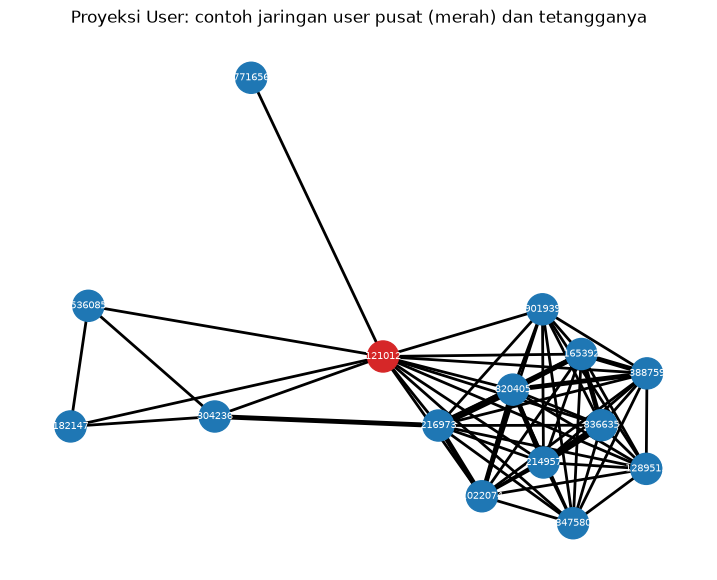

In [27]:
import networkx as nx
import matplotlib.pyplot as plt

X_bin = (X_user > 0).astype(int)   # 1 = pernah berinteraksi, 0 = tidak

# Pilih user "pusat" secara acak (seed tetap, jadi bisa direproduksi),
# di antara user yang punya 3-8 item
rng = np.random.default_rng(42)
kandidat = np.where((per_user >= 3) & (per_user <= 8))[0]
pusat = rng.choice(kandidat)

# Berapa item yang sama antara user pusat dan setiap user lain
overlap = (X_bin @ X_bin[pusat].T).toarray().ravel()
overlap[pusat] = 0
tetangga = np.argsort(-overlap, kind="stable")[:15]
tetangga = tetangga[overlap[tetangga] > 0]
simpul = np.concatenate([[pusat], tetangga])

# Item sama antar user terpilih
sub = X_bin[simpul]
S = (sub @ sub.T).toarray()

G = nx.Graph()
G.add_nodes_from(range(len(simpul)))
for a in range(len(simpul)):
    for b in range(a + 1, len(simpul)):
        if S[a, b] > 0:
            G.add_edge(a, b, weight=int(S[a, b]))

print("User pusat (visitorId):", user_ids[pusat], "| jumlah item:", per_user[pusat])
print("Jumlah tetangga       :", len(tetangga))
print("Simpul / garis di plot:", G.number_of_nodes(), "/", G.number_of_edges())

pos = nx.spring_layout(G, seed=42)
warna = ["tab:red" if a == 0 else "tab:blue" for a in G.nodes]
lebar = [0.5 + 1.5 * G[u][v]["weight"] for u, v in G.edges]
label = {a: str(user_ids[simpul[a]]) for a in G.nodes}

plt.figure(figsize=(9, 7))
nx.draw_networkx(
    G, pos, node_color=warna, width=lebar, node_size=500,
    labels=label, font_size=7, font_color="white",
)
plt.title("Proyeksi User: contoh jaringan user pusat (merah) dan tetangganya")
plt.axis("off")
plt.show()

**Plot `networkx` proyeksi User (contoh)**

Seluruh graf (171.802 simpul) tidak bisa digambar dengan jelas, sehingga yang divisualisasikan adalah satu contoh jaringan kecil.

- Satu user pusat dipilih secara acak dengan seed tetap (`seed = 42`, sehingga bisa direproduksi), di antara user yang memiliki 3 sampai 8 item.
- Simpul lain adalah user yang memiliki item yang sama dengan user pusat (maksimal 15 user dengan item sama terbanyak).
- Dua user dihubungkan oleh satu garis jika pernah berinteraksi dengan item yang sama. Semakin tebal garis, semakin banyak item yang sama.

**Hasil:**
- User pusat: `visitorId` 121012 (merah), memiliki 3 item.
- Jumlah tetangga: 14 user. Jumlahnya kurang dari 15 karena hanya 14 user lain di P1 yang memiliki item yang sama dengan user pusat.
- Plot berisi 15 simpul dan 63 garis (maksimum yang mungkin 105 garis).

**Uraian:**
- Sebagian besar tetangga saling terhubung rapat membentuk gerombol. Hal ini terjadi karena satu item yang dilihat oleh *n* user menghubungkan semua user tersebut satu sama lain (n(n-1)/2 garis).
- Satu user di bagian atas hanya terhubung dengan user pusat, artinya ia hanya berbagi item dengan user pusat.
- Proyeksi User menghubungkan user lewat item yang sama, sehingga jumlah garis dapat bertambah cepat seiring bertambahnya user pada satu item.

In [28]:
X_item = X_user.T.tocsr()   # transpos: baris = item, kolom = user

baris_i, kolom_i = X_item.shape
per_item = X_item.getnnz(axis=1)

print("VSM Item")
print("Dimensi vektor (jumlah user) :", kolom_i)
print("Shape matriks (item x user)  :", X_item.shape)
print("Sel bernilai (non-zero)      :", X_item.nnz)
print(f"Kepadatan (density)          : {X_item.nnz / (baris_i * kolom_i):.6%}")
print(f"Ukuran bila disimpan penuh   : {baris_i * kolom_i * 8 / 1e9:.1f} GB")
print(f"Ukuran bentuk sparse         : {(X_item.data.nbytes + X_item.indices.nbytes + X_item.indptr.nbytes) / 1e6:.1f} MB")
print("User berbeda per item        : min", per_item.min(),
      "| rata-rata", round(per_item.mean(), 2),
      "| median", int(np.median(per_item)),
      "| maks", per_item.max())
print(f"Item yang hanya 1 user       : {(per_item == 1).mean():.1%}")
print("Item terpopuler (itemId)     :", item_ids[per_item.argmax()])

VSM Item
Dimensi vektor (jumlah user) : 171802
Shape matriks (item x user)  : (83507, 171802)
Sel bernilai (non-zero)      : 247127
Kepadatan (density)          : 0.001723%
Ukuran bila disimpan penuh   : 114.8 GB
Ukuran bentuk sparse         : 3.3 MB
User berbeda per item        : min 1 | rata-rata 2.96 | median 1 | maks 368
Item yang hanya 1 user       : 53.5%
Item terpopuler (itemId)     : 5411


**5. Vector Space Model (VSM) untuk simpul `Item`**

Setiap `Item` direpresentasikan sebagai satu vektor. Kolom matriks adalah setiap `Visitor`, dan isi selnya adalah kekuatan interaksi visitor terhadap item tersebut (bobot sama dengan poin 4: `VIEWED` = 1, `ADDED_TO_CART` = 3, `BOUGHT` = 5). Matriks **Item x User** diperoleh dari transpos matriks User x Item pada poin 4.

**Karakteristik:**

| Aspek | Nilai |
|---|---|
| Dimensi vektor (jumlah user) | 171.802 |
| Shape matriks (item x user) | (83.507, 171.802) |
| Sel bernilai (non-zero) | 247.127 |
| Kepadatan (*density*) | 0,001723% |
| Ukuran jika disimpan penuh | 114,8 GB |
| Ukuran bentuk *sparse* | 3,3 MB |
| User berbeda per item | min 1, rata-rata 2,96, median 1, maks 368 |
| Item dengan hanya 1 user | 53,5% |
| Item terpopuler | `itemId` 5411 |

**Perbandingan dengan VSM User (poin 4):**

| Aspek | VSM User | VSM Item |
|---|---|---|
| Shape | (171.802, 83.507) | (83.507, 171.802) |
| Dimensi vektor | 83.507 | 171.802 |
| Jumlah vektor (baris) | 171.802 | 83.507 |
| Rata-rata sel bernilai per vektor | 1,44 | 2,96 |
| Vektor dengan hanya 1 sel bernilai | 83,1% | 53,5% |
| Maks sel bernilai per vektor | 755 | 368 |

**Uraian:**
- Kedua matriks berisi data yang sama (247.127 sel bernilai, kepadatan 0,0017%), hanya sudut pandangnya yang dibalik. Keduanya sangat jarang (*sparse*), sehingga wajib disimpan dalam bentuk *sparse* (3,3 MB dibanding sekitar 115 GB jika penuh).
- Matriks Item memiliki lebih sedikit vektor (83.507 dibanding 171.802), dan rata-rata setiap vektornya berisi lebih banyak sel bernilai (2,96 dibanding 1,44).
- Distribusinya miring: lebih dari separuh item (53,5%) hanya disentuh satu user, sedangkan item terpopuler disentuh hingga 368 user.

Item pusat (itemId)   : 42927 | jumlah user: 4
Item lain yang terhubung ke pusat: 59
Jumlah tetangga di plot: 15
Simpul / garis di plot : 16 / 100


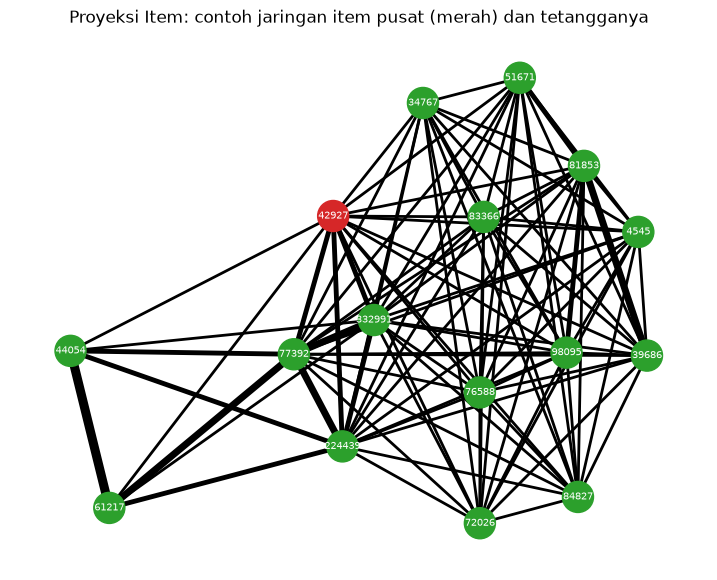

In [29]:
X_bin_i = (X_item > 0).astype(int)   # 1 = pernah disentuh user, 0 = tidak

# Item pusat dipilih acak (seed tetap), di antara item yang disentuh 3-8 user
rng = np.random.default_rng(42)
kandidat_i = np.where((per_item >= 3) & (per_item <= 8))[0]
pusat_i = rng.choice(kandidat_i)

# Berapa user yang sama antara item pusat dan setiap item lain
overlap_i = (X_bin_i @ X_bin_i[pusat_i].T).toarray().ravel()
overlap_i[pusat_i] = 0
tetangga_i = np.argsort(-overlap_i, kind="stable")[:15]
tetangga_i = tetangga_i[overlap_i[tetangga_i] > 0]
simpul_i = np.concatenate([[pusat_i], tetangga_i])

# User yang sama antar item terpilih
sub_i = X_bin_i[simpul_i]
S_i = (sub_i @ sub_i.T).toarray()

G_i = nx.Graph()
G_i.add_nodes_from(range(len(simpul_i)))
for a in range(len(simpul_i)):
    for b in range(a + 1, len(simpul_i)):
        if S_i[a, b] > 0:
            G_i.add_edge(a, b, weight=int(S_i[a, b]))

print("Item pusat (itemId)   :", item_ids[pusat_i], "| jumlah user:", per_item[pusat_i])
print("Item lain yang terhubung ke pusat:", int((overlap_i > 0).sum()))
print("Jumlah tetangga di plot:", len(tetangga_i))
print("Simpul / garis di plot :", G_i.number_of_nodes(), "/", G_i.number_of_edges())

pos_i = nx.spring_layout(G_i, seed=42)
warna_i = ["tab:red" if a == 0 else "tab:green" for a in G_i.nodes]
lebar_i = [0.5 + 1.5 * G_i[u][v]["weight"] for u, v in G_i.edges]
label_i = {a: str(item_ids[simpul_i[a]]) for a in G_i.nodes}

plt.figure(figsize=(9, 7))
nx.draw_networkx(
    G_i, pos_i, node_color=warna_i, width=lebar_i, node_size=500,
    labels=label_i, font_size=7, font_color="white",
)
plt.title("Proyeksi Item: contoh jaringan item pusat (merah) dan tetangganya")
plt.axis("off")
plt.show()

**Plot `networkx` proyeksi Item (contoh)**

Seperti pada proyeksi User, yang digambar adalah satu contoh jaringan kecil.

- Satu item pusat dipilih secara acak dengan seed tetap (`seed = 42`), di antara item yang disentuh 3 sampai 8 user.
- Simpul lain adalah item yang pernah disentuh oleh user yang sama dengan item pusat (maksimal 15 item dengan user bersama terbanyak).
- Dua item dihubungkan oleh satu garis jika pernah disentuh oleh user yang sama. Semakin tebal garis, semakin banyak user yang sama.

**Hasil:**
- Item pusat: `itemId` 42927 (merah), disentuh oleh 4 user.
- Item lain yang terhubung ke pusat: 59 item, dan 15 di antaranya digambar.
- Plot berisi 16 simpul dan 100 garis (maksimum yang mungkin 120 garis, sekitar 83%).

**Uraian:**
- Walaupun item pusat hanya disentuh 4 user, ia terhubung ke 59 item lain. Satu user yang menyentuh banyak item akan menghubungkan semua item tersebut satu sama lain.
- Plot Item lebih rapat dibanding plot User (83% dibanding 60% garis dari maksimum), tetapi keduanya hanya sampel kecil dan belum menggambarkan kepadatan seluruh graf proyeksi. Perbandingan yang terukur dilakukan pada poin 6.
- Pasangan item `44054` dan `61217` dihubungkan oleh garis paling tebal, yang berarti keduanya disentuh oleh banyak user yang sama.

In [30]:
import time

def ukur_proyeksi(nama, X_bin_mat):
    mulai = time.perf_counter()
    P = (X_bin_mat @ X_bin_mat.T).tocsr()     # sel (a,b) = jumlah yang sama antara a dan b
    detik = time.perf_counter() - mulai

    n = P.shape[0]
    garis = (P.nnz - n) // 2                  # buang diagonal (a dengan dirinya sendiri), bagi 2 karena simetris
    derajat = P.getnnz(axis=1) - 1            # jumlah tetangga tiap simpul
    mem_mb = (P.data.nbytes + P.indices.nbytes + P.indptr.nbytes) / 1e6
    kepadatan = garis / (n * (n - 1) / 2)

    print(f"Proyeksi {nama}")
    print(f"  Simpul                : {n}")
    print(f"  Garis                 : {garis}")
    print(f"  Kepadatan             : {kepadatan:.6%}")
    print(f"  Waktu hitung          : {detik:.2f} detik")
    print(f"  Memori (sparse)       : {mem_mb:.1f} MB")
    print(f"  Simpul tanpa tetangga : {(derajat == 0).mean():.1%}")
    print(f"  Tetangga per simpul   : rata-rata {derajat.mean():.1f} | median {int(np.median(derajat))} | maks {derajat.max()}")
    print()
    return P

P_user = ukur_proyeksi("User-User", (X_user > 0).astype(np.int32))
P_item = ukur_proyeksi("Item-Item", (X_item > 0).astype(np.int32))

Proyeksi User-User
  Simpul                : 171802
  Garis                 : 1400037
  Kepadatan             : 0.009487%
  Waktu hitung          : 0.17 detik
  Memori (sparse)       : 24.5 MB
  Simpul tanpa tetangga : 17.2%
  Tetangga per simpul   : rata-rata 16.3 | median 5 | maks 7661

Proyeksi Item-Item
  Simpul                : 83507
  Garis                 : 1902731
  Kepadatan             : 0.054572%
  Waktu hitung          : 0.14 detik
  Memori (sparse)       : 31.4 MB
  Simpul tanpa tetangga : 48.3%
  Tetangga per simpul   : rata-rata 45.6 | median 1 | maks 3993



**6. Perbandingan proyeksi User-User dan Item-Item**

Kedua proyeksi dibangun dari seluruh data P1. Dua simpul dihubungkan jika punya sesuatu yang sama: dua user terhubung jika pernah berinteraksi dengan item yang sama, dan dua item terhubung jika pernah disentuh oleh user yang sama. Proyeksi dihitung dari matriks biner 0/1 (`X @ X.T`).

| Aspek | Proyeksi User-User | Proyeksi Item-Item |
|---|---|---|
| Jumlah simpul | 171.802 | 83.507 |
| Jumlah garis | 1.400.037 | 1.902.731 |
| Kepadatan | 0,009487% | 0,054572% |
| Waktu hitung | 0,17 detik | 0,14 detik |
| Memori (*sparse*) | 24,5 MB | 31,4 MB |
| Simpul tanpa tetangga | 17,2% | 48,3% |
| Tetangga per simpul | rata-rata 16,3, median 5, maks 7.661 | rata-rata 45,6, median 1, maks 3.993 |

**Efisiensi:**
- Waktu hitung keduanya di bawah 1 detik dan selisihnya (0,03 detik) terlalu kecil untuk dijadikan pembeda.
- Proyeksi User-User lebih hemat: garisnya sekitar 36% lebih sedikit (1,40 juta dibanding 1,90 juta) dan memorinya sekitar 28% lebih kecil.

**Efektivitas (cakupan):**
- Pada proyeksi Item-Item, 48,3% item tidak memiliki tetangga, dan median tetangganya hanya 1. Hampir separuh item tidak dapat dicarikan item yang mirip.
- Pada proyeksi User-User, simpul tanpa tetangga hanya 17,2% dan median tetangganya 5.
- Rata-rata tetangga Item-Item yang lebih tinggi (45,6) tidak menunjukkan kualitas lebih baik, karena mediannya hanya 1. Nilai rata-rata ditarik oleh beberapa simpul hub. Sebagai gambaran, satu user yang menyentuh 755 item dapat menghasilkan hingga 755 x 754 / 2 = 284.635 garis antar-item, sekitar 15% dari seluruh garis Item-Item.
- Kepadatan Item-Item yang lebih tinggi disebabkan jumlah simpulnya lebih sedikit dan adanya hub tersebut, bukan karena strukturnya lebih baik.

**Kesimpulan:** proyeksi **User-User** dipilih karena lebih efektif (cakupan lebih luas) dan lebih efisien (garis dan memori lebih sedikit). Proyeksi ini juga sesuai dengan tugas Analytics, yaitu mencari tetangga terdekat (KNN) dari seorang user untuk menghasilkan rekomendasi item.

**Keterbatasan:** persentase simpul tanpa tetangga dihitung pada seluruh P1. User yang dievaluasi pada tahap rekomendasi dipilih dari visitor yang muncul di P1 dan P2 (4.921 visitor), sehingga cakupan untuk kelompok itu bisa berbeda dan belum diukur.

In [31]:
from scipy.sparse import diags

# 1) Normalisasi tiap baris jadi panjang 1, supaya perkalian titik = cosine
norma = np.sqrt(np.asarray(X_user.power(2).sum(axis=1)).ravel())
X_norm = diags(1 / norma) @ X_user

# 2) Pilih user acuan secara acak (seed tetap)
bersama = set(p1["visitorid"]) & set(p2["visitorid"])
derajat_user = P_user.getnnz(axis=1) - 1
di_kedua = np.isin(user_ids, list(bersama))
kandidat_acuan = np.where(
    di_kedua & (per_user >= 3) & (per_user <= 8) & (derajat_user >= 10)
)[0]
print("Kandidat user acuan:", len(kandidat_acuan))

rng = np.random.default_rng(42)
acuan = rng.choice(kandidat_acuan)
print("User acuan (visitorId):", user_ids[acuan], "| jumlah item:", per_user[acuan],
      "| tetangga di proyeksi:", derajat_user[acuan])

# 3) Cosine similarity user acuan terhadap semua user
sims = (X_norm @ X_norm[acuan].T).toarray().ravel()
item_sama = (X_bin @ X_bin[acuan].T).toarray().ravel()
sims[acuan] = -1   # buang dirinya sendiri

# 4) Urutkan: cosine terbesar, lalu item sama terbanyak, lalu visitorId terkecil
urutan = np.lexsort((user_ids, -item_sama, -sims))
top5 = urutan[:5]

print("\nUser dengan kemiripan > 0:", int((sims > 0).sum()))
print("User yang bernilai sama dengan peringkat 1:", int((np.isclose(sims, sims[top5[0]])).sum()))
print("\n5 user paling mirip:")
print(pd.DataFrame({
    "visitorId": user_ids[top5],
    "cosine": sims[top5].round(4),
    "item_sama": item_sama[top5],
    "jumlah_item": per_user[top5],
}).to_string(index=False))

Kandidat user acuan: 687
User acuan (visitorId): 146146 | jumlah item: 3 | tetangga di proyeksi: 131

User dengan kemiripan > 0: 131
User yang bernilai sama dengan peringkat 1: 8

5 user paling mirip:
 visitorId  cosine  item_sama  jumlah_item
    116986  0.8729          1            1
    121241  0.8729          1            1
    221074  0.8729          1            1
    374707  0.8729          1            1
    502440  0.8729          1            1


**7. Perhitungan similarity pada proyeksi User-User (percobaan pertama)**

Proyeksi User-User menentukan siapa yang bertetangga (punya item yang sama), dan kemiripan diukur dengan **cosine similarity** pada vektor berbobot dari poin 4. Tiap baris matriks dinormalisasi menjadi panjang 1, sehingga perkalian titik dua baris sama dengan cosine-nya. Nilai 1 berarti arah vektor sama persis, dan 0 berarti tidak ada item yang sama.

**Pemilihan user acuan** (acak, `seed = 42`, sehingga bisa direproduksi), dari user yang memenuhi tiga syarat: muncul di P1 dan P2, memiliki 3 sampai 8 item, dan memiliki minimal 10 tetangga di proyeksi. Terdapat 687 kandidat. User terpilih: `visitorId` 146146 (3 item, 131 tetangga).

**Aturan urutan:** cosine terbesar, jika seri maka item yang sama terbanyak, jika masih seri maka `visitorId` terkecil.

**Hasil:** 5 user dengan cosine tertinggi

| visitorId | cosine | item sama | jumlah item |
|---|---|---|---|
| 116986 | 0,8729 | 1 | 1 |
| 121241 | 0,8729 | 1 | 1 |
| 221074 | 0,8729 | 1 | 1 |
| 374707 | 0,8729 | 1 | 1 |
| 502440 | 0,8729 | 1 | 1 |

**Temuan:**
- Jumlah user dengan kemiripan di atas 0 adalah 131, sama dengan jumlah tetangga di proyeksi. Ini konsisten karena hanya user yang berbagi item yang bisa memiliki cosine di atas 0.
- Terdapat **8 user yang seri di peringkat 1**, sehingga kelima user di atas dipilih oleh aturan seri, bukan karena benar-benar lebih mirip.
- Penyebabnya: untuk user yang hanya memiliki satu item `j`, cosine dengan user acuan sama dengan (bobot acuan pada `j`) / (panjang vektor acuan), tidak bergantung pada bobot user tersebut. Semua user satu-item yang menyentuh item dengan bobot acuan yang sama akan seri.
- Syarat

In [32]:
rng = np.random.default_rng(42)
urutan_kandidat = rng.permutation(kandidat_acuan)

def hitung_peringkat(idx_acuan):
    sims = (X_norm @ X_norm[idx_acuan].T).toarray().ravel()
    item_sama = (X_bin @ X_bin[idx_acuan].T).toarray().ravel()
    sims[idx_acuan] = -1
    urutan = np.lexsort((user_ids, -item_sama, -sims))
    return sims, item_sama, urutan

for percobaan, c in enumerate(urutan_kandidat, start=1):
    sims, item_sama, urutan = hitung_peringkat(c)
    if sims[urutan[4]] - sims[urutan[5]] > 1e-9:   # peringkat 5 harus beda dari peringkat 6
        acuan = c
        break
else:
    raise RuntimeError("Tidak ada kandidat tanpa seri di batas peringkat 5")

top5 = urutan[:5]
print("Percobaan ke-", percobaan, "dari", len(urutan_kandidat), "kandidat")
print("User acuan (visitorId):", user_ids[acuan], "| jumlah item:", per_user[acuan],
      "| tetangga di proyeksi:", derajat_user[acuan])
print("User dengan kemiripan > 0:", int((sims > 0).sum()))

tampil = urutan[:6]
print("\n5 user paling mirip (+ peringkat 6 sebagai pembanding batas):")
print(pd.DataFrame({
    "peringkat": range(1, 7),
    "visitorId": user_ids[tampil],
    "cosine": sims[tampil].round(4),
    "item_sama": item_sama[tampil],
    "jumlah_item": per_user[tampil],
}).to_string(index=False))

Percobaan ke- 8 dari 687 kandidat
User acuan (visitorId): 759615 | jumlah item: 3 | tetangga di proyeksi: 41
User dengan kemiripan > 0: 41

5 user paling mirip (+ peringkat 6 sebagai pembanding batas):
 peringkat  visitorId  cosine  item_sama  jumlah_item
         1     988244  0.9129          2            2
         2     556125  0.8660          2            2
         3    1306829  0.8660          2            2
         4     548517  0.8165          1            1
         5     791625  0.7947          1            3
         6    1247201  0.6667          1            3


**7. Perhitungan similarity: pemilihan ulang user acuan**

Pada percobaan pertama (user acuan `146146`), terdapat 8 user yang seri di peringkat 1, sehingga 5 user teratas ditentukan oleh aturan seri, bukan oleh kemiripan yang sebenarnya. Karena itu user acuan dipilih ulang dengan aturan berikut, agar hasilnya bisa direproduksi:

1. Kandidat sama seperti sebelumnya: 687 user yang muncul di P1 dan P2, memiliki 3 sampai 8 item, dan memiliki minimal 10 tetangga di proyeksi User-User.
2. Urutan kandidat diacak dengan `seed = 42`.
3. Dipakai kandidat pertama yang nilai peringkat 5-nya **lebih besar** dari peringkat 6, sehingga himpunan 5 user teratas tidak ditentukan oleh aturan seri.

Kandidat ke-8 yang lolos. Tujuh kandidat sebelumnya dilewati karena nilai peringkat 5 dan peringkat 6-nya seri.

**User acuan:** `visitorId` 759615 (3 item, 41 tetangga di proyeksi).

| Peringkat | visitorId | cosine | item sama | jumlah item |
|---|---|---|---|---|
| 1 | 988244 | 0,9129 | 2 | 2 |
| 2 | 556125 | 0,8660 | 2 | 2 |
| 3 | 1306829 | 0,8660 | 2 | 2 |
| 4 | 548517 | 0,8165 | 1 | 1 |
| 5 | 791625 | 0,7947 | 1 | 3 |
| *6 (pembanding batas)* | *1247201* | *0,6667* | *1* | *3* |

**Temuan:**
- Jumlah user dengan kemiripan di atas 0 adalah 41, sama dengan jumlah tetangga di proyeksi, sehingga konsisten.
- Peringkat 5 (0,7947) lebih besar dari peringkat 6 (0,6667), sehingga himpunan 5 user teratas tidak ambigu.
- Peringkat 2 dan 3 seri (0,8660). Keduanya masuk 5 teratas, dan urutannya ditentukan oleh `visitorId` terkecil, sehingga tidak memengaruhi himpunan 5 user teratas.
- Hasil percobaan pertama dipertahankan di atas sebagai dokumentasi proses.

Jenis relasi di seluruh graf SEBELUM similarity:
       relasi  jumlah
       VIEWED  299629
ADDED_TO_CART    7535
       BOUGHT    2473

Subgraf 6 user (acuan + 5 teratas): simpul 11 | panah 13


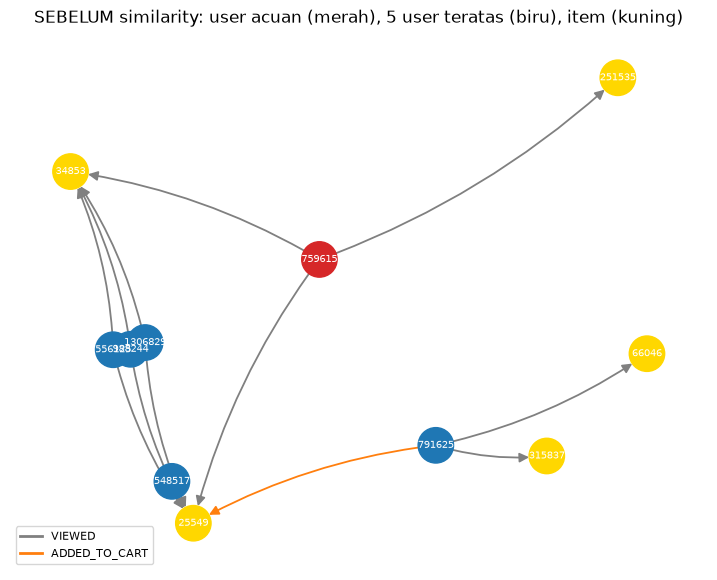

In [38]:
from matplotlib.lines import Line2D

acuan_id = int(user_ids[acuan])
top5_ids = [int(x) for x in user_ids[top5]]
ids_graf = [acuan_id] + top5_ids

WARNA_RELASI = {"VIEWED": "gray", "ADDED_TO_CART": "tab:orange",
                "BOUGHT": "tab:green", "SIMILAR_TO": "tab:purple"}
URUTAN_KUAT = ["BOUGHT", "ADDED_TO_CART", "VIEWED"]

def bangun_graf(baris_relasi, baris_similar=()):
    G = nx.DiGraph()
    jenis_per_pasangan = {}
    for r in baris_relasi:
        jenis_per_pasangan.setdefault((r["visitor"], r["item"]), set()).add(r["relasi"])
    for (v, i), jenis in jenis_per_pasangan.items():
        terkuat = next(t for t in URUTAN_KUAT if t in jenis)   # satu panah per pasangan, ambil yang terkuat
        G.add_edge(("U", v), ("I", i), relasi=terkuat)
    for s in baris_similar:
        G.add_edge(("U", s["dari"]), ("U", s["ke"]), relasi="SIMILAR_TO", skor=s["skor"])
    return G

def gambar_graf(G, judul, pos):
    warna_node = ["tab:red" if n == ("U", acuan_id)
                  else "tab:blue" if n[0] == "U" else "gold" for n in G.nodes]
    plt.figure(figsize=(9, 7))
    nx.draw_networkx_nodes(G, pos, node_color=warna_node, node_size=650)
    nx.draw_networkx_labels(G, pos, labels={n: str(n[1]) for n in G.nodes},
                            font_size=7, font_color="white")
    ada = set()
    for relasi, warna in WARNA_RELASI.items():
        garis = [(u, v) for u, v, d in G.edges(data=True) if d["relasi"] == relasi]
        if garis:
            ada.add(relasi)
            nx.draw_networkx_edges(G, pos, edgelist=garis, edge_color=warna,
                                   width=2.5 if relasi == "SIMILAR_TO" else 1.3,
                                   arrows=True, arrowsize=14, node_size=650,
                                   connectionstyle="arc3,rad=0.1")
    skor = {(u, v): f"{d['skor']:.4f}" for u, v, d in G.edges(data=True) if "skor" in d}
    if skor:
        nx.draw_networkx_edge_labels(G, pos, edge_labels=skor, font_size=7, font_color="tab:purple")
    plt.legend(handles=[Line2D([0], [0], color=WARNA_RELASI[r], lw=2, label=r) for r in WARNA_RELASI if r in ada],
               loc="lower left", fontsize=8)
    plt.title(judul)
    plt.axis("off")
    plt.show()

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    rel_awal, _, _ = driver.execute_query(
        "MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah ORDER BY jumlah DESC",
        database_="neo4j", routing_=RoutingControl.READ,
    )
    sub_awal, _, _ = driver.execute_query(
        "MATCH (v:Visitor)-[r]->(i:Item) WHERE v.visitorId IN $ids "
        "RETURN v.visitorId AS visitor, type(r) AS relasi, i.itemId AS item",
        ids=ids_graf, database_="neo4j", routing_=RoutingControl.READ,
    )

print("Jenis relasi di seluruh graf SEBELUM similarity:")
print(pd.DataFrame([r.data() for r in rel_awal]).to_string(index=False))

G_awal = bangun_graf([r.data() for r in sub_awal])
print("\nSubgraf 6 user (acuan + 5 teratas): simpul", G_awal.number_of_nodes(),
      "| panah", G_awal.number_of_edges())

pos_sub = nx.spring_layout(G_awal, seed=42)   # posisi disimpan, dipakai lagi untuk gambar "sesudah"
gambar_graf(G_awal, "SEBELUM similarity: user acuan (merah), 5 user teratas (biru), item (kuning)", pos_sub)

**8. Kondisi graf SEBELUM perhitungan similarity**

Query yang dipakai:

```cypher
// Jenis relasi di seluruh graf
MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah ORDER BY jumlah DESC

// Subgraf: user acuan dan 5 user teratas beserta item yang disentuh
MATCH (v:Visitor)-[r]->(i:Item) WHERE v.visitorId IN $ids
RETURN v.visitorId AS visitor, type(r) AS relasi, i.itemId AS item
```

**Jenis relasi di seluruh graf:**

| Relasi | Jumlah |
|---|---|
| VIEWED | 299.629 |
| ADDED_TO_CART | 7.535 |
| BOUGHT | 2.473 |

Pada kondisi ini belum ada relasi `SIMILAR_TO`.

**Subgraf yang digambar:** user acuan `759615` (merah), 5 user teratas dari poin 7 (biru), dan item yang mereka sentuh (kuning), total 11 simpul dan 13 panah. Jika satu user memiliki lebih dari satu jenis relasi ke item yang sama, hanya jenis terkuat yang digambar (`BOUGHT` > `ADDED_TO_CART` > `VIEWED`).

**Pengamatan:**
- Lima item pada gambar adalah gabungan item dari keenam user. Item `34853` dan `25549` menjadi penghubung antara user acuan dan sebagian besar user lain. Tiga item lainnya hanya disentuh satu user di subgraf ini.
- Tiga user di sebelah kiri (`556125`, `988244`, `1306829`) memiliki pola item yang sama, sehingga posisinya hampir menumpuk pada gambar.
- Keenam user belum ada yang melakukan `BOUGHT`. Hubungan antar-user belum tergambar langsung, hanya terlihat lewat item yang sama.

similar to neo4j

In [39]:
pasangan = [
    {"dari": acuan_id, "ke": int(user_ids[idx]),
     "skor": round(float(sims[idx]), 6), "peringkat": n}
    for n, idx in enumerate(top5, start=1)
]

CYPHER_TULIS = """
UNWIND $pasangan AS p
MATCH (a:Visitor {visitorId: p.dari})
MATCH (b:Visitor {visitorId: p.ke})
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.score = p.skor, r.peringkat = p.peringkat, r.metode = 'cosine'
RETURN count(r) AS relasi_ditulis
"""

CYPHER_BACA = """
MATCH (a:Visitor {visitorId: $acuan})-[r:SIMILAR_TO]->(b:Visitor)
RETURN a.visitorId AS dari, b.visitorId AS ke, r.score AS score, r.peringkat AS peringkat
ORDER BY r.score DESC, b.visitorId ASC
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    tulis, _, _ = driver.execute_query(CYPHER_TULIS, pasangan=pasangan, database_="neo4j")
    print("Relasi SIMILAR_TO ditulis:", tulis[0]["relasi_ditulis"])

    hasil, _, _ = driver.execute_query(
        CYPHER_BACA, acuan=acuan_id, database_="neo4j", routing_=RoutingControl.READ,
    )
    jenis, _, _ = driver.execute_query(
        "MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah ORDER BY jumlah DESC",
        database_="neo4j", routing_=RoutingControl.READ,
    )

print("\nNilai similarity yang tersimpan di graf:")
print(pd.DataFrame([r.data() for r in hasil]).to_string(index=False))
print("\nJenis relasi di seluruh graf SESUDAH similarity:")
print(pd.DataFrame([r.data() for r in jenis]).to_string(index=False))
print("\nUrutan sama dengan hasil Python (poin 7)?", [r["ke"] for r in hasil] == top5_ids)

Relasi SIMILAR_TO ditulis: 5

Nilai similarity yang tersimpan di graf:
  dari      ke    score  peringkat
759615  988244 0.912871          1
759615  556125 0.866025          2
759615 1306829 0.866025          3
759615  548517 0.816497          4
759615  791625 0.794719          5

Jenis relasi di seluruh graf SESUDAH similarity:
       relasi  jumlah
       VIEWED  299629
ADDED_TO_CART    7535
       BOUGHT    2473
   SIMILAR_TO       5

Urutan sama dengan hasil Python (poin 7)? True


**7b. Menuliskan nilai similarity ke graf**

Kelima nilai cosine tertinggi ditulis ke Neo4j sebagai relasi baru `SIMILAR_TO` dari user acuan (`759615`) ke masing-masing 5 user teratas. Relasi menyimpan properti `score` (nilai cosine), `peringkat`, dan `metode` (`cosine`).

```cypher
UNWIND $pasangan AS p
MATCH (a:Visitor {visitorId: p.dari})
MATCH (b:Visitor {visitorId: p.ke})
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.score = p.skor, r.peringkat = p.peringkat, r.metode = 'cosine'
RETURN count(r) AS relasi_ditulis
```

- `UNWIND` memecah daftar pasangan menjadi baris-baris, dan dua `MATCH` mencari simpul user acuan dan user tujuan.
- `MERGE` membuat relasi berarah hanya jika belum ada, sehingga menjalankan sel ini berulang tidak menggandakan relasi.
- `SET` menempelkan nilai similarity pada relasi.
- Skor dibulatkan 6 angka di belakang koma agar dua nilai yang secara matematika sama (peringkat 2 dan 3) tersimpan identik.

**Hasil yang tersimpan di graf:**

| dari | ke | score | peringkat |
|---|---|---|---|
| 759615 | 988244 | 0,912871 | 1 |
| 759615 | 556125 | 0,866025 | 2 |
| 759615 | 1306829 | 0,866025 | 3 |
| 759615 | 548517 | 0,816497 | 4 |
| 759615 | 791625 | 0,794719 | 5 |

**Verifikasi:** relasi `SIMILAR_TO` yang tertulis berjumlah 5. Jumlah relasi lama tidak berubah (`VIEWED` 299.629, `ADDED_TO_CART` 7.535, `BOUGHT` 2.473). Urutan 5 user dari Neo4j sama dengan hasil perhitungan Python pada poin 7.

5 record dengan similarity tertinggi (query Cypher):
 visitorId  similarity
    988244    0.912871
    556125    0.866025
   1306829    0.866025
    548517    0.816497
    791625    0.794719

Subgraf SESUDAH: simpul 11 | panah 18


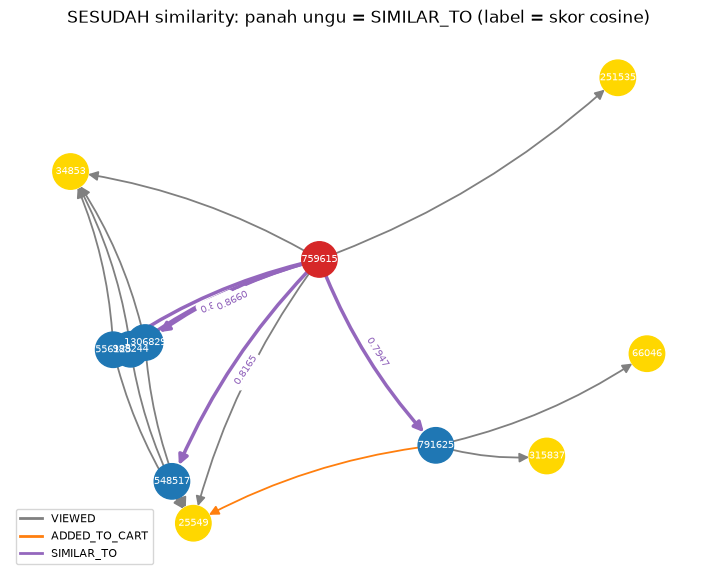

In [40]:
CYPHER_TOP5 = """
MATCH (a:Visitor {visitorId: $acuan})-[s:SIMILAR_TO]->(b:Visitor)
RETURN b.visitorId AS visitorId, s.score AS similarity
ORDER BY s.score DESC, b.visitorId ASC
LIMIT 5
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    top5_db, _, _ = driver.execute_query(
        CYPHER_TOP5, acuan=acuan_id, database_="neo4j", routing_=RoutingControl.READ,
    )
    sub_akhir, _, _ = driver.execute_query(
        "MATCH (v:Visitor)-[r]->(i:Item) WHERE v.visitorId IN $ids "
        "RETURN v.visitorId AS visitor, type(r) AS relasi, i.itemId AS item",
        ids=ids_graf, database_="neo4j", routing_=RoutingControl.READ,
    )
    sim_akhir, _, _ = driver.execute_query(
        "MATCH (a:Visitor {visitorId: $acuan})-[s:SIMILAR_TO]->(b:Visitor) "
        "RETURN a.visitorId AS dari, b.visitorId AS ke, s.score AS skor",
        acuan=acuan_id, database_="neo4j", routing_=RoutingControl.READ,
    )

print("5 record dengan similarity tertinggi (query Cypher):")
print(pd.DataFrame([r.data() for r in top5_db]).to_string(index=False))

G_akhir = bangun_graf([r.data() for r in sub_akhir], [r.data() for r in sim_akhir])
print("\nSubgraf SESUDAH: simpul", G_akhir.number_of_nodes(), "| panah", G_akhir.number_of_edges())

gambar_graf(G_akhir, "SESUDAH similarity: panah ungu = SIMILAR_TO (label = skor cosine)", pos_sub)

**7a. Query Cypher untuk 5 record dengan similarity tertinggi**

User acuan: `visitorId` 759615 (dipilih pada poin 7).

```cypher
MATCH (a:Visitor {visitorId: $acuan})-[s:SIMILAR_TO]->(b:Visitor)
RETURN b.visitorId AS visitorId, s.score AS similarity
ORDER BY s.score DESC, b.visitorId ASC
LIMIT 5
```

- `MATCH ... -[s:SIMILAR_TO]->` mencari semua relasi `SIMILAR_TO` yang keluar dari user acuan.
- `ORDER BY s.score DESC` mengurutkan dari similarity terbesar. `b.visitorId ASC` menentukan urutan jika ada skor yang seri.
- `LIMIT 5` hanya mengambil lima baris teratas.

**Hasil:**

| visitorId | similarity |
|---|---|
| 988244 | 0,912871 |
| 556125 | 0,866025 |
| 1306829 | 0,866025 |
| 548517 | 0,816497 |
| 791625 | 0,794719 |

Hasil ini sama dengan perhitungan Python pada poin 7 dan dengan nilai yang ditulis pada poin 7b.

**8. Kondisi graf SESUDAH perhitungan similarity**

Query untuk mengambil subgraf yang digambar:

```cypher
// Relasi user ke item (sama dengan kondisi sebelum)
MATCH (v:Visitor)-[r]->(i:Item) WHERE v.visitorId IN $ids
RETURN v.visitorId AS visitor, type(r) AS relasi, i.itemId AS item

// Relasi similarity (baru)
MATCH (a:Visitor {visitorId: $acuan})-[s:SIMILAR_TO]->(b:Visitor)
RETURN a.visitorId AS dari, b.visitorId AS ke, s.score AS skor
```

**Perbandingan sebelum dan sesudah:**

| Aspek | Sebelum | Sesudah |
|---|---|---|
| Relasi `SIMILAR_TO` di seluruh graf | 0 | 5 |
| Total relasi di seluruh graf | 309.637 | 309.642 |
| Simpul pada subgraf yang digambar | 11 | 11 |
| Panah pada subgraf yang digambar | 13 | 18 |

**Pengamatan:**
- Relasi lama tidak berubah (`VIEWED` 299.629, `ADDED_TO_CART` 7.535, `BOUGHT` 2.473). Yang bertambah hanya 5 relasi `SIMILAR_TO`.
- Pada gambar, panah ungu menghubungkan user acuan (merah) langsung ke 5 user teratas (biru), dengan skor cosine sebagai label. Sebelumnya hubungan antar-user hanya terlihat lewat item yang sama.
- Simpul tidak bertambah, karena `SIMILAR_TO` menghubungkan simpul `Visitor` yang sudah ada.
- Tiga user di sebelah kiri saling menumpuk karena pola itemnya sama persis, sehingga sebagian label skor tertutup. Nilai pastinya ada pada tabel poin 7a.

### analisis

In [41]:
# Item yang disentuh tiap visitor di P1 dan di P2
p1_items = p1.groupby("visitorid")["itemid"].apply(set)
p2_items = p2.groupby("visitorid")["itemid"].apply(set)

# Kolam: ada di P1 dan P2, punya item baru di P2, dan punya tetangga di proyeksi
pool = []
for v in sorted(bersama):
    baru = p2_items[v] - p1_items[v]
    idx = int(np.searchsorted(user_ids, v))
    if len(baru) > 0 and derajat_user[idx] > 0:
        pool.append(int(v))

print("Visitor di P1 dan P2                          :", len(bersama))
print("Dengan >=1 item baru di P2 dan >=1 tetangga   :", len(pool))

# Pilih satu user secara acak (seed tetap, jadi bisa direproduksi)
rng = np.random.default_rng(42)
user_uji = int(rng.choice(pool))
idx_uji = int(np.searchsorted(user_ids, user_uji))
item_baru = p2_items[user_uji] - p1_items[user_uji]

print("\nUser uji (visitorId):", user_uji)
print("Item di P1          :", len(p1_items[user_uji]), "item ->", sorted(p1_items[user_uji]))
print("Tetangga di proyeksi:", derajat_user[idx_uji])
print("Item di P2          :", len(p2_items[user_uji]), "item")
print("Item baru di P2     :", len(item_baru), "item ->", sorted(item_baru))

d2 = p2[(p2["visitorid"] == user_uji) & (p2["itemid"].isin(item_baru))]
print("Item baru di P2 per jenis event:", d2.groupby("event")["itemid"].nunique().to_dict())

Visitor di P1 dan P2                          : 4921
Dengan >=1 item baru di P2 dan >=1 tetangga   : 3021

User uji (visitorId): 117385
Item di P1          : 1 item -> [370572]
Tetangga di proyeksi: 2
Item di P2          : 8 item
Item baru di P2     : 8 item -> [41081, 125203, 141103, 182407, 393203, 428065, 429753, 445840]
Item baru di P2 per jenis event: {'view': 8}


### 2.2 Analytics

**1. Pemilihan user secara acak (dapat direproduksi)**

**Kolam pemilihan:** visitor yang muncul di P1 dan P2 (4.921 visitor), karena hanya mereka yang memiliki data uji di P2. Dua syarat tambahan (ditentukan sendiri, bukan ketentuan soal):
1. Memiliki minimal 1 item **baru** di P2, yaitu item yang belum pernah disentuh di P1. Rekomendasi hanya mengusulkan item yang belum pernah disentuh user, sehingga item P2 yang sudah ada di P1 tidak mungkin terkena.
2. Memiliki minimal 1 tetangga di proyeksi User-User.

Kolam akhir berjumlah **3.021 visitor**.

**Proses acak:** kolam diurutkan berdasarkan `visitorId`, lalu satu user dipilih dengan `numpy.random.default_rng(42).choice(...)`. Urutan kolam dan seed yang tetap membuat hasilnya selalu sama.

**User terpilih: `visitorId` 117385**

| Aspek | Nilai |
|---|---|
| Item di P1 | 1 item (`370572`) |
| Tetangga di proyeksi User-User | 2 |
| Item di P2 | 8 item |
| Item baru di P2 | 8 item: 41081, 125203, 141103, 182407, 393203, 428065, 429753, 445840 |
| Jenis event item baru di P2 | `view` (8) |

**Catatan:**
- Seluruh item baru di P2 berjenis `view`. Tidak ada yang berjenis `addtocart` atau `transaction`.
- User ini hanya memiliki 1 item di P1 dan 2 tetangga, sehingga sinyal untuk rekomendasinya sangat terbatas.

In [42]:
K = 5

# 1) KNN: cosine user uji terhadap semua user
sims_u = (X_norm @ X_norm[idx_uji].T).toarray().ravel()
sama_u = (X_bin @ X_bin[idx_uji].T).toarray().ravel()
sims_u[idx_uji] = -1
urut = np.lexsort((user_ids, -sama_u, -sims_u))
knn = [int(n) for n in urut[:K] if sims_u[n] > 0]

print("k =", K, "| tetangga nyata (kemiripan > 0):", len(knn))
print(pd.DataFrame({
    "visitorId": user_ids[knn],
    "cosine": sims_u[knn].round(4),
    "item_sama": sama_u[knn],
    "jumlah_item": per_user[knn],
}).to_string(index=False))

# 2) Skor item = jumlah (cosine tetangga x bobot tetangga pada item)
skor = np.zeros(len(item_ids))
jml_tetangga = np.zeros(len(item_ids), dtype=int)
for n in knn:
    baris = X_user[n].toarray().ravel()
    skor += sims_u[n] * baris
    jml_tetangga += (baris > 0)

# 3) Buang item yang sudah pernah disentuh user uji di P1
sudah = X_user[idx_uji].toarray().ravel() > 0
skor[sudah] = 0

kandidat = np.where(skor > 0)[0]
print("\nItem kandidat (milik tetangga, belum disentuh user uji):", len(kandidat))

urut_item = kandidat[np.lexsort((item_ids[kandidat], -jml_tetangga[kandidat], -skor[kandidat]))]
rekom = urut_item[:3]

print("\nKandidat teratas (maks 5 ditampilkan):")
tampil = urut_item[:5]
print(pd.DataFrame({
    "peringkat": range(1, len(tampil) + 1),
    "itemId": item_ids[tampil],
    "skor": skor[tampil].round(4),
    "jumlah_tetangga": jml_tetangga[tampil],
}).to_string(index=False))

print("\nItem yang direkomendasikan (maks 3):", [int(i) for i in item_ids[rekom]])

k = 5 | tetangga nyata (kemiripan > 0): 2
 visitorId  cosine  item_sama  jumlah_item
    232433  0.5774          1            3
   1234838  0.5000          1            4

Item kandidat (milik tetangga, belum disentuh user uji): 5

Kandidat teratas (maks 5 ditampilkan):
 peringkat  itemId   skor  jumlah_tetangga
         1  314073 0.5774                1
         2  352573 0.5774                1
         3  100567 0.5000                1
         4  102197 0.5000                1
         5  273761 0.5000                1

Item yang direkomendasikan (maks 3): [314073, 352573, 100567]


**1a. Skrip Python rekomendasi KNN**

Skrip pada sel di atas bekerja dengan aturan berikut:

1. **Tetangga (KNN):** user dengan cosine similarity tertinggi terhadap user uji (cosine yang sama dengan poin 7), maksimal **k = 5**, dan hanya yang cosine-nya di atas 0. Jika seri: item sama terbanyak, lalu `visitorId` terkecil.
2. **Skor item** = jumlah dari (cosine tetangga x bobot tetangga pada item tersebut). Tetangga yang lebih mirip dan interaksi yang lebih kuat (`BOUGHT` > `ADDED_TO_CART` > `VIEWED`) menghasilkan skor lebih tinggi.
3. **Item yang dibuang:** item yang sudah pernah disentuh user uji di P1.
4. **Rekomendasi:** 3 item dengan skor tertinggi. Jika seri: jumlah tetangga yang menyentuh item terbanyak, lalu `itemId` terkecil.

**1b. Hasil rekomendasi untuk user `117385` (k = 5)**

Tetangga yang ditemukan:

| visitorId | cosine | item sama | jumlah item |
|---|---|---|---|
| 232433 | 0,5774 | 1 | 3 |
| 1234838 | 0,5000 | 1 | 4 |

Kandidat item (5 item, urut dari skor tertinggi):

| Peringkat | itemId | Skor | Jumlah tetangga |
|---|---|---|---|
| 1 | 314073 | 0,5774 | 1 |
| 2 | 352573 | 0,5774 | 1 |
| 3 | 100567 | 0,5000 | 1 |
| 4 | 102197 | 0,5000 | 1 |
| 5 | 273761 | 0,5000 | 1 |

**3 item yang direkomendasikan: `314073`, `352573`, `100567`.**

**Catatan:**
- Hanya 2 tetangga yang memiliki kemiripan di atas 0 (k = 5 tidak terisi penuh), karena user uji hanya memiliki 1 item di P1 dan hanya 2 tetangga di proyeksi User-User.
- Kedua tetangga berbagi satu item dengan user uji (`370572`, satu-satunya item user uji di P1).
- Item peringkat 3 sampai 5 memiliki skor yang sama (0,5000). Item `100567` terpilih karena aturan seri (`itemId` terkecil), bukan karena lebih relevan daripada `102197` dan `273761`.

In [43]:
K_EVAL = 5
rekom_ids = [int(i) for i in item_ids[rekom]]

# Kunci jawaban pilihan A: semua item yang disentuh user uji di P2
relevan_A = set(int(i) for i in p2_items[user_uji])
# Pilihan B: hanya yang dimasukkan ke keranjang atau dibeli di P2
relevan_B = set(int(i) for i in p2[
    (p2["visitorid"] == user_uji) & (p2["event"].isin(["addtocart", "transaction"]))
]["itemid"])

def hit_at_k(rekom, relevan, k):
    return int(any(i in relevan for i in rekom[:k]))

def dcg(rels):
    return sum(r / np.log2(pos + 2) for pos, r in enumerate(rels))   # pos mulai dari 0, jadi log2(pos + 2)

def ndcg_at_k(rekom, relevan, k):
    rels = [1 if i in relevan else 0 for i in rekom[:k]]
    idcg = dcg([1] * min(len(relevan), k))
    return dcg(rels), idcg, (dcg(rels) / idcg if idcg > 0 else float("nan"))

print("User uji        :", user_uji)
print("Rekomendasi     :", rekom_ids)
print("Kunci A (P2)    :", len(relevan_A), "item ->", sorted(relevan_A))
print("Kunci B (P2)    :", len(relevan_B), "item (keranjang atau beli)")
print("Item rekomendasi yang kena kunci A:", sorted(set(rekom_ids) & relevan_A))

print("\nRincian per posisi (kunci A):")
print(pd.DataFrame({
    "peringkat": range(1, len(rekom_ids) + 1),
    "itemId": rekom_ids,
    "relevan": [int(i in relevan_A) for i in rekom_ids],
    "diskon": [round(1 / np.log2(p + 1), 4) for p in range(1, len(rekom_ids) + 1)],
}).to_string(index=False))

dcg_A, idcg_A, ndcg_A = ndcg_at_k(rekom_ids, relevan_A, K_EVAL)
print(f"\nPilihan A -> Hit@{K_EVAL}: {hit_at_k(rekom_ids, relevan_A, K_EVAL)}"
      f" | DCG: {dcg_A:.4f} | IDCG: {idcg_A:.4f} | NDCG@{K_EVAL}: {ndcg_A:.4f}")
print("Pilihan B -> kunci kosong, Hit dan NDCG tidak terdefinisi" if not relevan_B else "Pilihan B tersedia")

User uji        : 117385
Rekomendasi     : [314073, 352573, 100567]
Kunci A (P2)    : 8 item -> [41081, 125203, 141103, 182407, 393203, 428065, 429753, 445840]
Kunci B (P2)    : 0 item (keranjang atau beli)
Item rekomendasi yang kena kunci A: []

Rincian per posisi (kunci A):
 peringkat  itemId  relevan  diskon
         1  314073        0  1.0000
         2  352573        0  0.6309
         3  100567        0  0.5000

Pilihan A -> Hit@5: 0 | DCG: 0.0000 | IDCG: 2.9485 | NDCG@5: 0.0000
Pilihan B -> kunci kosong, Hit dan NDCG tidak terdefinisi


**2. Evaluasi rekomendasi: Hit@5 dan NDCG@5**

**Kunci jawaban (ground truth):** item yang disentuh user uji (`117385`) di P2 (8 item), apa pun jenis eventnya. Kunci alternatif yang hanya memakai `addtocart` atau `transaction` tidak dapat dipakai karena kosong, sebab seluruh 8 item baru di P2 berjenis `view`.

**Asumsi:** daftar rekomendasi berisi 3 item (sesuai soal) dan batas evaluasi @5. Ketiga item dihitung semuanya, dan posisi 4 sampai 5 yang kosong bernilai 0.

**Definisi:**
- **Hit@5** = 1 jika ada item rekomendasi (maksimal 5 teratas) yang ada di kunci jawaban, selain itu 0.
- **DCG@5** = jumlah dari `relevan / log2(posisi + 1)` pada tiap posisi, sehingga item relevan di posisi atas bernilai lebih besar.
- **IDCG@5** = DCG jika urutannya sempurna (item relevan di posisi teratas). Karena terdapat 8 item relevan dan batas 5, IDCG@5 = 1 + 0,6309 + 0,5 + 0,4307 + 0,3869 = 2,9485.
- **NDCG@5** = DCG@5 / IDCG@5, bernilai 0 sampai 1.

**Hasil:**

| Peringkat | itemId | Relevan | Diskon |
|---|---|---|---|
| 1 | 314073 | 0 | 1,0000 |
| 2 | 352573 | 0 | 0,6309 |
| 3 | 100567 | 0 | 0,5000 |

| Metrik | Nilai |
|---|---|
| Hit@5 | **0** |
| DCG@5 | 0,0000 |
| IDCG@5 | 2,9485 |
| NDCG@5 | **0,0000** |

**Interpretasi:**
- Tidak ada satu pun dari 3 item rekomendasi yang ada di kunci jawaban (8 item di P2), sehingga Hit@5 dan NDCG@5 bernilai 0.
- Hasil ini berasal dari **satu user saja** dan tidak dapat dijadikan kesimpulan tentang kualitas metode secara umum. User uji hanya memiliki 1 item di P1 dan 2 tetangga di proyeksi (k = 5 tidak terisi penuh), sehingga hanya tersedia 5 item kandidat. Kedelapan item di P2 juga bukan item milik kedua tetangga tersebut.
- User uji dipilih secara acak dengan seed tetap dan **tidak dipilih ulang** setelah melihat hasilnya, agar hasilnya tidak dipilih-pilih.

In [44]:
def rekomendasi_knn(idx, k=5, n_rekom=3):
    sims = (X_norm @ X_norm[idx].T).toarray().ravel()
    sama = (X_bin @ X_bin[idx].T).toarray().ravel()
    sims[idx] = -1
    nz = np.where(sims > 0)[0]                       # hanya user yang mirip (cosine > 0)
    if len(nz) == 0:
        return [], 0
    urut = nz[np.lexsort((user_ids[nz], -sama[nz], -sims[nz]))]
    knn = urut[:k]

    sub = X_user[knn]                                 # vektor item para tetangga
    skor = np.asarray(sub.T @ sims[knn]).ravel()      # jumlah (cosine x bobot)
    jml = np.asarray((sub > 0).sum(axis=0)).ravel()   # berapa tetangga menyentuh item
    skor[X_user[idx].indices] = 0                     # buang item yang sudah disentuh di P1

    kand = np.where(skor > 0)[0]
    if len(kand) == 0:
        return [], len(knn)
    urut_item = kand[np.lexsort((item_ids[kand], -jml[kand], -skor[kand]))]
    return [int(i) for i in item_ids[urut_item[:n_rekom]]], len(knn)

urut_pop = np.lexsort((item_ids, -per_item))          # item paling banyak disentuh user berbeda di depan

def rekomendasi_populer(idx, n_rekom=3):
    sudah = set(X_user[idx].indices)
    hasil = []
    for j in urut_pop:
        if j not in sudah:
            hasil.append(int(item_ids[j]))
            if len(hasil) == n_rekom:
                break
    return hasil

# Cek dulu: hasilnya harus sama dengan Sel 34 untuk user uji
print("Sama dengan Sel 34 untuk user", user_uji, "?",
      rekomendasi_knn(idx_uji, k=K)[0] == rekom_ids)

baris = []
mulai = time.time()
for v in tqdm(pool, desc="Evaluasi user"):
    idx = int(np.searchsorted(user_ids, v))
    relevan = set(int(i) for i in p2_items[v])
    rek_knn, n_tet = rekomendasi_knn(idx, k=K)
    rek_pop = rekomendasi_populer(idx)
    baris.append({
        "visitorId": int(v), "tetangga": n_tet, "n_rekom": len(rek_knn),
        "hit_knn": hit_at_k(rek_knn, relevan, K_EVAL),
        "ndcg_knn": ndcg_at_k(rek_knn, relevan, K_EVAL)[2],
        "hit_pop": hit_at_k(rek_pop, relevan, K_EVAL),
        "ndcg_pop": ndcg_at_k(rek_pop, relevan, K_EVAL)[2],
    })
hasil_eval = pd.DataFrame(baris)
print(f"Selesai dalam {time.time() - mulai:.0f} detik\n")

print("Jumlah user dievaluasi:", len(hasil_eval))
print("Jumlah rekomendasi KNN per user:", hasil_eval["n_rekom"].value_counts().sort_index().to_dict())

ringkas = pd.DataFrame({
    "metode": ["KNN (k=5)", "Populer (pembanding)"],
    "user_kena": [int(hasil_eval["hit_knn"].sum()), int(hasil_eval["hit_pop"].sum())],
    "Hit@5": [hasil_eval["hit_knn"].mean(), hasil_eval["hit_pop"].mean()],
    "NDCG@5": [hasil_eval["ndcg_knn"].mean(), hasil_eval["ndcg_pop"].mean()],
})
print("\nRata-rata seluruh kolam:")
print(ringkas.round(4).to_string(index=False))

print("\nHit@5 KNN menurut jumlah tetangga nyata (maks k = 5):")
print(hasil_eval.groupby("tetangga")
      .agg(jumlah_user=("visitorId", "count"), user_kena=("hit_knn", "sum"), Hit5=("hit_knn", "mean"))
      .round(4).to_string())

Sama dengan Sel 34 untuk user 117385 ? True


Evaluasi user: 100%|██████████| 3021/3021 [00:33<00:00, 90.81it/s] 

Selesai dalam 33 detik

Jumlah user dievaluasi: 3021
Jumlah rekomendasi KNN per user: {0: 1716, 1: 293, 2: 170, 3: 842}

Rata-rata seluruh kolam:
              metode  user_kena  Hit@5  NDCG@5
           KNN (k=5)         66 0.0218  0.0102
Populer (pembanding)         15 0.0050  0.0021

Hit@5 KNN menurut jumlah tetangga nyata (maks k = 5):
          jumlah_user  user_kena    Hit5
tetangga                                
1                 306          5  0.0163
2                 233          2  0.0086
3                 174          1  0.0057
4                 173          3  0.0173
5                2135         55  0.0258


In [45]:
print("Sel 34 :", rekom_ids)
print("Fungsi :", rekomendasi_knn(idx_uji, k=K)[0])

Sel 34 : [314073, 352573, 100567]
Fungsi : [314073, 352573, 100567]


**Evaluasi pelengkap: seluruh kolam user (di luar permintaan soal)**

Evaluasi pada user acak (`117385`) hanya mencakup satu user. Sebagai pelengkap, prosedur yang **sama persis** (KNN k = 5, skor = jumlah cosine x bobot, item yang sudah disentuh di P1 dibuang, 3 item teratas, kunci jawaban = semua item yang disentuh user di P2) dijalankan untuk **seluruh 3.021 user di kolam**. Tidak ada user yang dipilih atau dibuang. Fungsi yang dipakai diuji lebih dulu dan menghasilkan rekomendasi yang sama dengan sel sebelumnya untuk user `117385`.

**Pembanding sederhana:** merekomendasikan 3 item yang paling banyak disentuh user berbeda di P1 (dan belum disentuh user tersebut), sama untuk semua orang.

**Hasil rata-rata seluruh kolam:**

| Metode | User kena | Hit@5 | NDCG@5 |
|---|---|---|---|
| KNN (k = 5) | 66 | 0,0218 | 0,0102 |
| Populer (pembanding) | 15 | 0,0050 | 0,0021 |

**Jumlah item yang berhasil direkomendasikan KNN per user:**

| Jumlah item | Jumlah user | Persentase |
|---|---|---|
| 0 | 1.716 | 56,8% |
| 1 | 293 | 9,7% |
| 2 | 170 | 5,6% |
| 3 | 842 | 27,9% |

**Hit@5 KNN menurut jumlah tetangga (cosine > 0, maksimal 5):**

| Jumlah tetangga | Jumlah user | User kena | Hit@5 |
|---|---|---|---|
| 1 | 306 | 5 | 0,0163 |
| 2 | 233 | 2 | 0,0086 |
| 3 | 174 | 1 | 0,0057 |
| 4 | 173 | 3 | 0,0173 |
| 5 | 2.135 | 55 | 0,0258 |

**Interpretasi:**
- KNN menghasilkan lebih banyak user yang terkena dibanding rekomendasi populer (66 dibanding 15 user), tetapi nilai keduanya kecil.
- Sebanyak 1.716 user (56,8%) tidak mendapat rekomendasi KNN sama sekali dan dihitung Hit = 0. Dugaan penyebabnya: item milik para tetangga seluruhnya sudah pernah disentuh user tersebut (belum diukur).
- User tanpa rekomendasi tidak mungkin terkena, sehingga di antara 1.305 user yang mendapat minimal 1 rekomendasi, 66 user (5,06%) terkena.
- Hasil Hit@5 = 0 pada user acak `117385` merupakan hasil yang paling umum: 2.955 dari 3.021 user (97,8%) memiliki Hit@5 = 0.
- Hit@5 tidak naik secara teratur terhadap jumlah tetangga. Kelompok 1 sampai 4 tetangga kecil (maksimal 306 user dan 1 sampai 5 user terkena), sehingga pengaruh jumlah tetangga belum dapat disimpulkan.

**Keterbatasan:**
- Kolam sudah disaring (ada di P1 dan P2, minimal 1 item baru di P2, minimal 1 tetangga), sehingga angka ini tidak berlaku untuk seluruh pengunjung toko.
- Kunci jawaban memperhitungkan seluruh jenis interaksi di P2, termasuk `view`.
- Hanya satu pembanding sederhana yang dipakai.